# YCSB (dbfs) Bench Results and Buffer-Pool Metrics

This notebook loads the YCSB benchmark artifacts under the selected dbfs result directory, summarizes the workload run, plots throughput/latency trends, and visualizes buffer-pool hit rate plus ARC state when ARC counters are available.


In [1]:
from pathlib import Path
import json
import re
from IPython.display import display

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use('ggplot')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

# result_dir = Path(
#     '/Users/yohasebe/Documents/dbfs/benchmarking/results/20260804-094406_arc-read-scan/ycsb/dbfs'
# )
result_dir = Path(
    '/Users/yohasebe/Documents/dbfs/before/benchmarking/results/20260804-100318_arc-read-scan/ycsb/dbfs'
)
summary_suffix = '.summary.json'
metrics_suffix = '.metrics.json'
params_suffix = '.params.json'
results_suffix = '.results.csv'
samples_suffix = '.samples.csv'
raw_suffix = '.raw.csv'
procedure_suffix = '.results.'
query_trace_filename = 'dbfs_query_trace.csv'
output_dir = result_dir / 'notebook_outputs'
output_dir.mkdir(exist_ok=True)

print(f'Result directory: {result_dir}')


Result directory: /Users/yohasebe/Documents/dbfs/before/benchmarking/results/20260804-100318_arc-read-scan/ycsb/dbfs


In [2]:
summary_paths = sorted(result_dir.glob(f'*{summary_suffix}'))
metrics_paths = sorted(result_dir.glob(f'*{metrics_suffix}'))
params_paths = sorted(result_dir.glob(f'*{params_suffix}'))
results_paths = sorted(result_dir.glob(f'*{results_suffix}'))
samples_paths = sorted(result_dir.glob(f'*{samples_suffix}'))
raw_paths = sorted(result_dir.glob(f'*{raw_suffix}'))
procedure_paths = sorted(result_dir.glob(f'*{procedure_suffix}*.csv'))
query_trace_path = result_dir / query_trace_filename

artifact_table = pd.DataFrame({
    'artifact': [
        'summary', 'metrics', 'params', 'results', 'samples', 'raw',
        'procedure_files', 'query_trace'
    ],
    'path': [
        summary_paths[-1].name if summary_paths else None,
        metrics_paths[-1].name if metrics_paths else None,
        params_paths[-1].name if params_paths else None,
        results_paths[-1].name if results_paths else None,
        samples_paths[-1].name if samples_paths else None,
        raw_paths[-1].name if raw_paths else None,
        f'{len(procedure_paths)} files' if procedure_paths else '0 files',
        query_trace_path.name if query_trace_path.exists() else None,
    ],
    'exists': [
        bool(summary_paths),
        bool(metrics_paths),
        bool(params_paths),
        bool(results_paths),
        bool(samples_paths),
        bool(raw_paths),
        bool(procedure_paths),
        query_trace_path.exists()
    ],
})
display(artifact_table)


,artifact,path,exists
0,summary,ycsb_2026-08-04_01-17-09.summary.json,True
1,metrics,ycsb_2026-08-04_01-17-09.metrics.json,True
2,params,ycsb_2026-08-04_01-17-09.params.json,True
3,results,ycsb_2026-08-04_01-17-09.results.csv,True
4,samples,ycsb_2026-08-04_01-17-09.samples.csv,True
5,raw,ycsb_2026-08-04_01-17-09.raw.csv,True
6,procedure_files,6 files,True
7,query_trace,dbfs_query_trace.csv,True


In [3]:
summary_path = summary_paths[-1]
metrics_path = metrics_paths[-1]
params_path = params_paths[-1]
results_path = results_paths[-1]
samples_path = samples_paths[-1]
raw_path = raw_paths[-1]

with summary_path.open(encoding='utf-8') as handle:
    summary = json.load(handle)
with metrics_path.open(encoding='utf-8') as handle:
    metrics = json.load(handle)
with params_path.open(encoding='utf-8') as handle:
    params = json.load(handle)

results_df = pd.read_csv(results_path)
samples_df = pd.read_csv(samples_path)
raw_df = pd.read_csv(raw_path)

procedure_dfs = {
    path.stem.split('.results.', 1)[1]: pd.read_csv(path)
    for path in procedure_paths
}

summary_table = pd.DataFrame([{
    'artifact_prefix':
    summary_path.name[:-len(summary_suffix)],
    'elapsed_seconds':
    summary['Elapsed Time (nanoseconds)'] / 1_000_000_000,
    'measured_requests':
    summary['Measured Requests'],
    'throughput_req_s':
    summary['Throughput (requests/second)'],
    'goodput_req_s':
    summary['Goodput (requests/second)'],
    'dbms_type':
    summary.get('DBMS Type'),
    'terminals':
    summary.get('terminals', params.get('terminals')),
    'scalefactor':
    summary.get('scalefactor', params.get('scalefactor'))
}])
display(summary_table)

print('Loaded summary keys:', list(summary.keys())[:10])
print('Loaded metrics keys:', list(metrics.keys())[:10])
print('Loaded params keys:', list(params.keys())[:10])
print('Results rows:', len(results_df), 'Samples rows:', len(samples_df),
      'Raw rows:', len(raw_df))
print('Procedure files:', ', '.join(sorted(procedure_dfs.keys())))


,artifact_prefix,elapsed_seconds,measured_requests,throughput_req_s,goodput_req_s,dbms_type,terminals,scalefactor
0,ycsb_2026-08-04_01-17-09,600.008,52114,86.856,112.264,POSTGRES,1,50


Loaded summary keys: ['Start timestamp (milliseconds)', 'Current Timestamp (milliseconds)', 'Elapsed Time (nanoseconds)', 'DBMS Type', 'DBMS Version', 'Benchmark Type', 'Final State', 'Measured Requests', 'isolation', 'scalefactor']
Loaded metrics keys: ['pg_stat_database', 'pg_stat_user_indexes', 'pg_statio_user_tables', 'pg_stat_bgwriter', 'pg_stat_user_tables', 'pg_statio_user_indexes', 'pg_stat_archiver', 'pg_stat_database_conflicts']
Loaded params keys: ['client_encoding', 'server_encoding', 'server_version']
Results rows: 120 Samples rows: 600 Raw rows: 52114
Procedure files: DeleteRecord, InsertRecord, ReadModifyWriteRecord, ReadRecord, ScanRecord, UpdateRecord


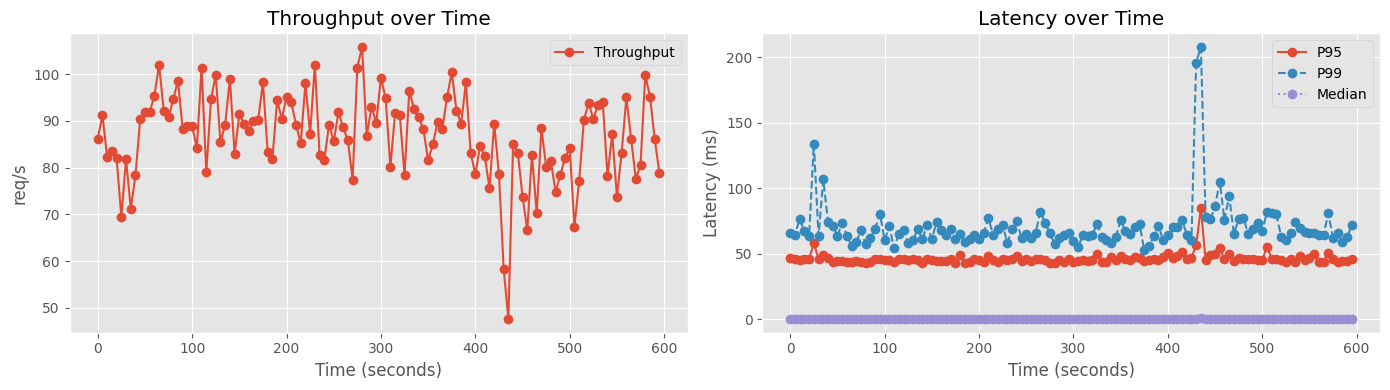

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(results_df['Time (seconds)'],
             results_df['Throughput (requests/second)'],
             marker='o',
             label='Throughput')
axes[0].set_title('Throughput over Time')
axes[0].set_xlabel('Time (seconds)')
axes[0].set_ylabel('req/s')
axes[0].legend()

axes[1].plot(results_df['Time (seconds)'],
             results_df['95th Percentile Latency (millisecond)'],
             marker='o',
             label='P95')
axes[1].plot(results_df['Time (seconds)'],
             results_df['99th Percentile Latency (millisecond)'],
             '--',
             marker='o',
             label='P99')
axes[1].plot(results_df['Time (seconds)'],
             results_df['Median Latency (millisecond)'],
             ':',
             marker='o',
             label='Median')
axes[1].set_title('Latency over Time')
axes[1].set_xlabel('Time (seconds)')
axes[1].set_ylabel('Latency (ms)')
axes[1].legend()

fig.tight_layout()
plt.show()


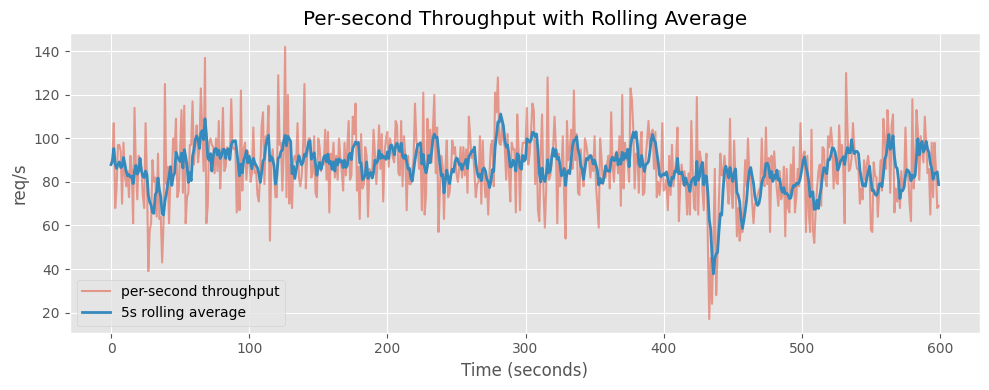

In [5]:
samples_for_plot = samples_df.copy()
samples_for_plot['rolling_5s'] = samples_for_plot[
    'Throughput (requests/second)'].rolling(5, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(samples_for_plot['Time (seconds)'],
        samples_for_plot['Throughput (requests/second)'],
        alpha=0.5,
        label='per-second throughput')
ax.plot(samples_for_plot['Time (seconds)'],
        samples_for_plot['rolling_5s'],
        linewidth=2,
        label='5s rolling average')
ax.set_title('Per-second Throughput with Rolling Average')
ax.set_xlabel('Time (seconds)')
ax.set_ylabel('req/s')
ax.legend()
fig.tight_layout()
plt.show()


,Procedure,Avg Throughput (req/s),Avg Latency (ms),Avg P95 Latency (ms)
3,ReadRecord,78.278,8.054,42.952
4,ScanRecord,8.578,44.394,82.276
0,DeleteRecord,0.000,-0.001,-0.001
1,InsertRecord,0.000,-0.001,-0.001
2,ReadModifyWriteRecord,0.000,-0.001,-0.001
5,UpdateRecord,0.000,-0.001,-0.001


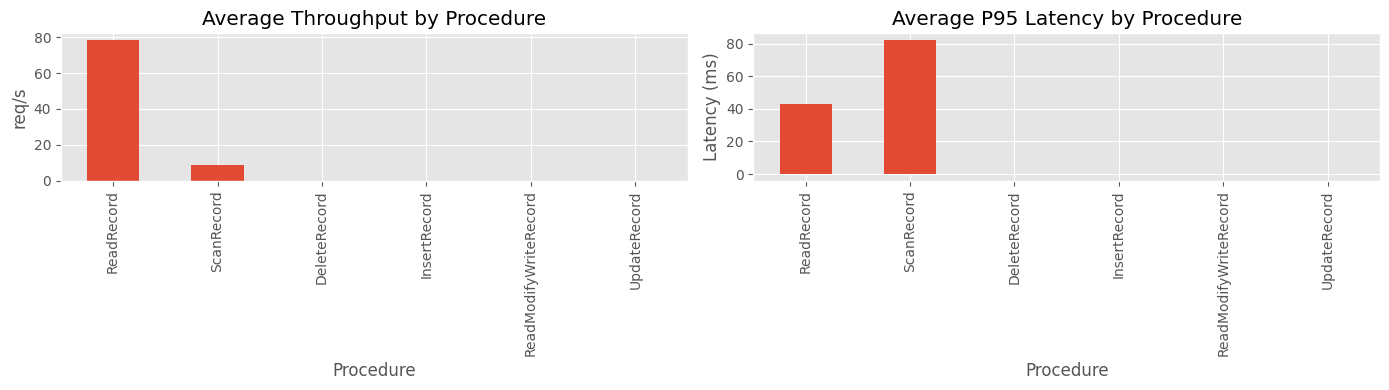

In [6]:
procedure_rows = []
for procedure_name, procedure_df in procedure_dfs.items():
    procedure_rows.append({
        'Procedure':
        procedure_name,
        'Avg Throughput (req/s)':
        procedure_df['Throughput (requests/second)'].mean(),
        'Avg Latency (ms)':
        procedure_df['Average Latency (millisecond)'].mean(),
        'Avg P95 Latency (ms)':
        procedure_df['95th Percentile Latency (millisecond)'].mean(),
    })

procedure_summary_df = pd.DataFrame(procedure_rows).sort_values(
    'Avg Throughput (req/s)', ascending=False)
display(procedure_summary_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
procedure_summary_df.set_index('Procedure')['Avg Throughput (req/s)'].plot(
    kind='bar', ax=axes[0])
axes[0].set_title('Average Throughput by Procedure')
axes[0].set_ylabel('req/s')

procedure_summary_df.set_index('Procedure')['Avg P95 Latency (ms)'].plot(
    kind='bar', ax=axes[1])
axes[1].set_title('Average P95 Latency by Procedure')
axes[1].set_ylabel('Latency (ms)')

fig.tight_layout()
plt.show()


,kind,shape_key,executions,total_elapsed_ms,mean_elapsed_ms,failures,sample_sql
0,QUERY,SELECT * FROM usertable WHERE YCSB_KEY=?,60741,"485,034.223",7.985,0,SELECT * FROM usertable WHERE YCSB_KEY=1436
1,QUERY,SELECT * FROM usertable WHERE YCSB_KEY>? AND Y...,6618,"283,788.239",42.881,0,SELECT * FROM usertable WHERE YCSB_KEY>17158 A...
2,QUERY,SELECT MAX(ycsb_key) FROM usertable,1,"2,851.718","2,851.718",0,SELECT MAX(ycsb_key) FROM usertable


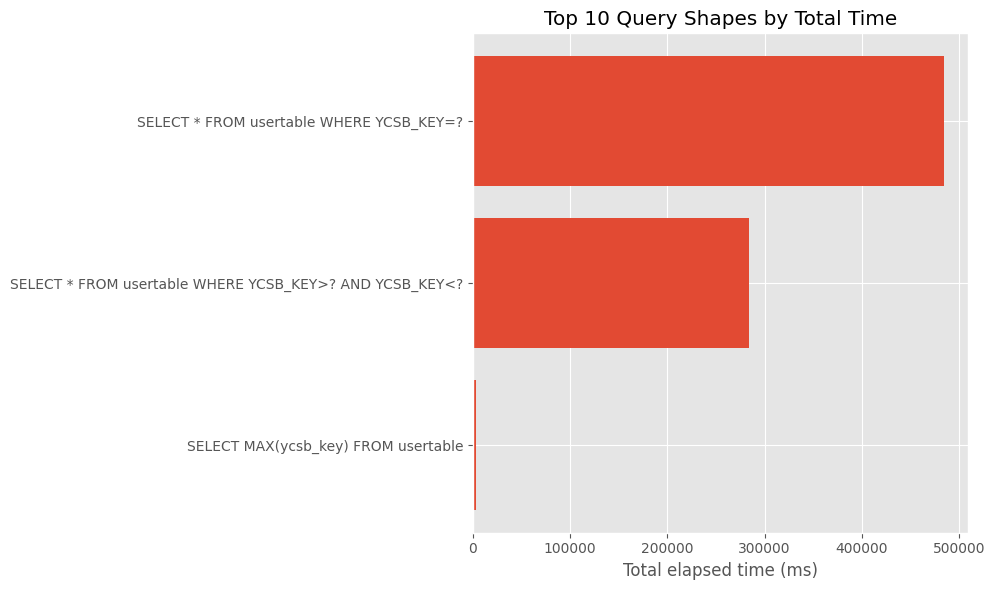

In [7]:
if query_trace_path.exists():
    query_trace_df = pd.read_csv(query_trace_path)
    query_trace_summary_df = query_trace_df.copy()
    query_trace_summary_df['total_elapsed_ms'] = query_trace_summary_df[
        'total_elapsed_us'] / 1000.0
    query_trace_summary_df[
        'mean_elapsed_ms'] = query_trace_summary_df['mean_elapsed_us'] / 1000.0
    query_trace_summary_df = query_trace_summary_df.sort_values(
        ['total_elapsed_ms', 'executions'], ascending=[False, False])
    display(query_trace_summary_df[[
        'kind', 'shape_key', 'executions', 'total_elapsed_ms',
        'mean_elapsed_ms', 'failures', 'sample_sql'
    ]].head(15))

    top_n = 10
    top_query_df = query_trace_summary_df.head(top_n)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top_query_df['shape_key'], top_query_df['total_elapsed_ms'])
    ax.invert_yaxis()
    ax.set_title(f'Top {top_n} Query Shapes by Total Time')
    ax.set_xlabel('Total elapsed time (ms)')
    plt.tight_layout()
    plt.show()
else:
    print('No dbfs_query_trace.csv found in the result directory.')


Using BenchBase measurement interval: 2026-08-04 01:07:08.729000+00:00 to 2026-08-04 01:17:08.757000+00:00.
Request and buffer-pool counters are relative to the last stats row before MEASURE.


,measurement_elapsed_seconds,pin_page_calls,resident_hits,misses,buffer_pool_hit_rate_pct
0,0.850,14122,8455,5667,59.871
1,1.860,25773,14581,11192,56.575
2,2.878,40315,23427,16888,58.110
3,3.878,52808,29273,23535,55.433
4,4.913,67297,38814,28483,57.676
5,5.932,77883,45249,32634,58.099
6,6.962,90399,51979,38420,57.500
7,7.983,104326,62617,41709,60.021
8,8.996,116660,68566,48094,58.774
9,9.995,130380,77180,53200,59.196


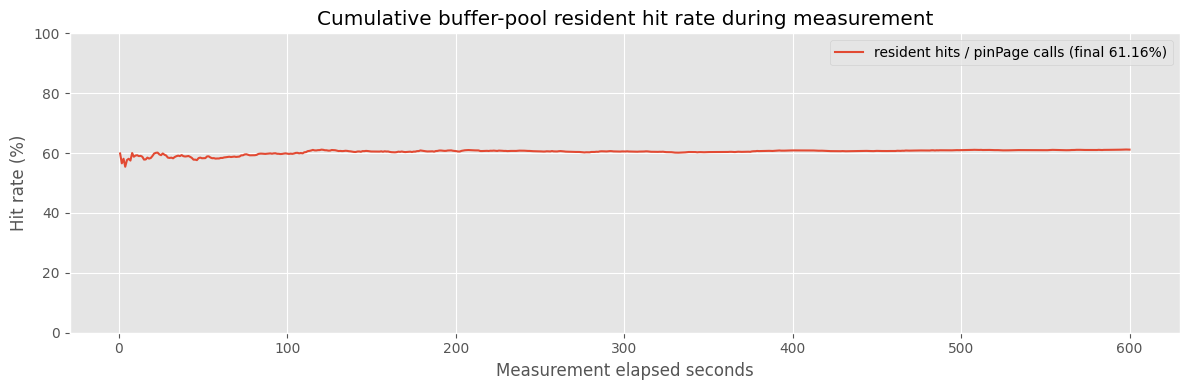

In [8]:
arc_log_path = result_dir / 'dbfs.compose.log'
arc_pattern = re.compile(r'buffer_pool_stats\s+(?P<stats>.*)$')
key_value_pattern = re.compile(r'(\w+)=(\d+)')
timestamp_pattern = re.compile(
    r'(\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}(?:\.\d+)?Z)')
benchbase_timestamp_pattern = re.compile(
    r'\[INFO \]\s+(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2},\d{3})')
arc_state_columns = ['arc_t1', 'arc_t2', 'arc_b1', 'arc_b2', 'arc_t1_target']
arc_request_columns = ['arc_b1_hits', 'arc_b2_hits', 'arc_cold_misses']
buffer_pool_counter_columns = ['pin_page_calls', 'resident_hits', 'misses']
arc_metric_columns = arc_state_columns + arc_request_columns
parsed_metric_columns = arc_metric_columns + buffer_pool_counter_columns


def find_benchbase_measurement_interval(result_dir):
    log_paths = [
        result_dir / 'benchbase_execute.log', result_dir / 'benchbase.log'
    ]
    log_path = next((path for path in log_paths if path.exists()), None)
    if log_path is None:
        return None, None

    start_at = None
    end_at = None
    with log_path.open(encoding='utf-8', errors='replace') as handle:
        for line in handle:
            timestamp_match = benchbase_timestamp_pattern.search(line)
            if not timestamp_match:
                continue
            timestamp = pd.to_datetime(timestamp_match.group(1).replace(
                ',', '.'),
                                       utc=True)
            if 'MEASURE' in line and start_at is None:
                start_at = timestamp
            if 'TERMINATE' in line:
                end_at = timestamp
                break
    return start_at, end_at


arc_rows = []
if arc_log_path.exists():
    for line in arc_log_path.read_text(encoding='utf-8',
                                       errors='replace').splitlines():
        match = arc_pattern.search(line)
        if not match:
            continue
        parsed_stats = {
            key: int(value)
            for key, value in key_value_pattern.findall(match.group('stats'))
        }
        if not any(metric in parsed_stats for metric in parsed_metric_columns):
            continue
        timestamp_match = timestamp_pattern.search(line)
        row = {
            column: parsed_stats[column]
            for column in parsed_metric_columns if column in parsed_stats
        }
        row['logged_at'] = pd.Timestamp(
            timestamp_match.group(1)) if timestamp_match else pd.NaT
        arc_rows.append(row)

arc_df = pd.DataFrame(arc_rows)
if not arc_df.empty:
    arc_df = arc_df.sort_values('logged_at').reset_index(drop=True)
    measurement_start_at, measurement_end_at = (
        find_benchbase_measurement_interval(result_dir))
    if measurement_start_at is not None and measurement_end_at is not None:
        baseline_rows = arc_df[arc_df['logged_at'] < measurement_start_at]
        baseline_row = (None
                        if baseline_rows.empty else baseline_rows.iloc[-1])
        arc_df = arc_df[(arc_df['logged_at'] >= measurement_start_at)
                        & (arc_df['logged_at'] <= measurement_end_at)].copy()
        arc_df = arc_df.reset_index(drop=True)
        if baseline_row is not None:
            measurement_counter_columns = (arc_request_columns +
                                           buffer_pool_counter_columns)
            for column in measurement_counter_columns:
                if column in arc_df.columns and column in baseline_row:
                    arc_df[column] = arc_df[column] - baseline_row[column]
        arc_df['measurement_elapsed_seconds'] = (
            arc_df['logged_at'] - measurement_start_at).dt.total_seconds()
        elapsed_column = 'measurement_elapsed_seconds'
        print(f'Using BenchBase measurement interval: '
              f'{measurement_start_at} to {measurement_end_at}.')
        print('Request and buffer-pool counters are relative to the last '
              'stats row before MEASURE.')
    else:
        arc_df['elapsed_seconds'] = (
            arc_df['logged_at'] -
            arc_df['logged_at'].iloc[0]).dt.total_seconds()
        elapsed_column = 'elapsed_seconds'
        print('BenchBase MEASURE/TERMINATE interval was not found; '
              'displaying all ARC stats.')
    has_hit_counters = all(column in arc_df.columns
                           for column in ['pin_page_calls', 'resident_hits'])
    if has_hit_counters:
        pin_calls = arc_df['pin_page_calls'].where(
            arc_df['pin_page_calls'] > 0)
        arc_df['buffer_pool_hit_rate_pct'] = (100.0 * arc_df['resident_hits'] /
                                              pin_calls)

    available_metric_columns = [
        column for column in parsed_metric_columns if column in arc_df.columns
    ]
    display_columns = [elapsed_column] + available_metric_columns
    if has_hit_counters:
        display_columns.append('buffer_pool_hit_rate_pct')
    display(arc_df.reindex(columns=display_columns).head(10))

    has_arc_state = all(column in arc_df.columns
                        for column in arc_state_columns)
    has_request_counters = all(column in arc_df.columns
                               for column in arc_request_columns)
    row_count = (2 * int(has_arc_state) + int(has_request_counters) +
                 int(has_hit_counters))
    fig, axes = plt.subplots(row_count,
                             1,
                             figsize=(12, 4 * row_count),
                             sharex=True)
    if row_count == 1:
        axes = [axes]

    next_axis = 0
    if has_arc_state:
        axes[next_axis].plot(arc_df[elapsed_column],
                             arc_df['arc_t1'],
                             label='arc_t1',
                             marker='o',
                             markersize=2)
        axes[next_axis].plot(arc_df[elapsed_column],
                             arc_df['arc_t2'],
                             label='arc_t2',
                             marker='x',
                             markersize=2)
        axes[next_axis].set_ylabel('List size')
        axes[next_axis].set_title('ARC T1/T2 list sizes')
        axes[next_axis].legend()
        next_axis += 1

        axes[next_axis].plot(arc_df[elapsed_column],
                             arc_df['arc_b1'],
                             label='arc_b1',
                             marker='o',
                             markersize=2)
        axes[next_axis].plot(arc_df[elapsed_column],
                             arc_df['arc_b2'],
                             label='arc_b2',
                             marker='x',
                             markersize=2)
        axes[next_axis].plot(arc_df[elapsed_column],
                             arc_df['arc_t1_target'],
                             label='arc_t1_target',
                             linestyle='--',
                             marker='s',
                             markersize=2)
        axes[next_axis].set_ylabel('List size / target')
        axes[next_axis].set_title('ARC B1/B2 list sizes and T1 target')
        axes[next_axis].legend()
        next_axis += 1
    if has_request_counters:
        for column in arc_request_columns:
            axes[next_axis].plot(arc_df[elapsed_column],
                                 arc_df[column],
                                 label=column)
        axes[next_axis].set_ylabel('Requests since MEASURE')
        axes[next_axis].set_title(
            'ARC non-resident requests during measurement')
        axes[next_axis].legend()
        next_axis += 1

    if has_hit_counters:
        hit_rate = arc_df['buffer_pool_hit_rate_pct']
        final_hit_rates = hit_rate.dropna()
        hit_rate_label = 'resident hits / pinPage calls'
        if not final_hit_rates.empty:
            hit_rate_label += f' (final {final_hit_rates.iloc[-1]:.2f}%)'
        axes[next_axis].plot(arc_df[elapsed_column],
                             hit_rate,
                             label=hit_rate_label)
        axes[next_axis].set_ylabel('Hit rate (%)')
        axes[next_axis].set_ylim(0, 100)
        axes[next_axis].set_title(
            'Cumulative buffer-pool resident hit rate during measurement')
        axes[next_axis].legend()
    axes[-1].set_xlabel('Measurement elapsed seconds')

    fig.tight_layout()
    plt.show()
else:
    print('No buffer-pool stats were found in the compose log.')


In [9]:
validation_rows = [
    {
        'artifact': 'summary',
        'rows': len(summary_table),
        'columns': ', '.join(summary_table.columns)
    },
    {
        'artifact': 'results',
        'rows': len(results_df),
        'columns': ', '.join(results_df.columns)
    },
    {
        'artifact': 'samples',
        'rows': len(samples_df),
        'columns': ', '.join(samples_df.columns)
    },
    {
        'artifact': 'procedure_summary',
        'rows': len(procedure_summary_df),
        'columns': ', '.join(procedure_summary_df.columns)
    },
    {
        'artifact':
        'query_trace',
        'rows':
        len(query_trace_df) if 'query_trace_df' in locals() else 0,
        'columns':
        ', '.join(query_trace_df.columns)
        if 'query_trace_df' in locals() else 'n/a'
    },
    {
        'artifact': 'arc_stats',
        'rows': len(arc_df) if 'arc_df' in locals() else 0,
        'columns': ', '.join(arc_df.columns) if 'arc_df' in locals() else 'n/a'
    },
]
validation_df = pd.DataFrame(validation_rows)
display(validation_df)

for name, table in {
        'summary_table': summary_table,
        'procedure_summary_df': procedure_summary_df,
        'validation_df': validation_df
}.items():
    path = output_dir / f'{name}.csv'
    table.to_csv(path, index=False)
    print(f'Saved {path}')

if 'fig' in locals() and fig is not None:
    output_path = output_dir / 'arc_metrics.png'
    fig.savefig(output_path, bbox_inches='tight')
    print(f'Saved {output_path}')


,artifact,rows,columns
0,summary,1,"artifact_prefix, elapsed_seconds, measured_req..."
1,results,120,"Time (seconds), Throughput (requests/second), ..."
2,samples,600,"Time (seconds), Requests, Throughput (requests..."
3,procedure_summary,6,"Procedure, Avg Throughput (req/s), Avg Latency..."
4,query_trace,3,"kind, shape_key, sample_sql, executions, total..."
5,arc_stats,592,"pin_page_calls, resident_hits, misses, logged_..."


Saved /Users/yohasebe/Documents/dbfs/before/benchmarking/results/20260804-100318_arc-read-scan/ycsb/dbfs/notebook_outputs/summary_table.csv
Saved /Users/yohasebe/Documents/dbfs/before/benchmarking/results/20260804-100318_arc-read-scan/ycsb/dbfs/notebook_outputs/procedure_summary_df.csv
Saved /Users/yohasebe/Documents/dbfs/before/benchmarking/results/20260804-100318_arc-read-scan/ycsb/dbfs/notebook_outputs/validation_df.csv
Saved /Users/yohasebe/Documents/dbfs/before/benchmarking/results/20260804-100318_arc-read-scan/ycsb/dbfs/notebook_outputs/arc_metrics.png
